In [43]:
import os
from glob import iglob
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder

import tensorflow as tf

# Data Pipeline

In [44]:
clinical = pd.read_csv('../data/Demo_data.csv')

X = clinical.drop(columns = ['Patient ID', 'Steatosis stage', 'Fibroscan S', 'Fibroscan F'])
Y = clinical[['Steatosis stage']]

encoder = OneHotEncoder(drop = 'if_binary', sparse_output = False)
X[['sex']] = encoder.fit_transform(X[['sex']])

In [45]:
# Load image map
imageMap = pd.read_csv('../data/BEHSOF_images.csv')

baseDir = os.path.join('..', 'data', 'image_Data')

imageMap['Patient ID']  = imageMap['Patient ID'].str.replace('\\Data\\', '')

def addImagePaths(row):
    p_id = row['Patient ID']
    imagePath = os.path.join(baseDir, p_id, '**/*.jpg')

    return list(iglob(imagePath, recursive = True))

# Create list of image paths
imageMap['Img Path'] = imageMap.apply(addImagePaths, axis = 1)

# Explode so each image path is on separate row
imageMap = imageMap.explode('Img Path')

# Visually examine
imageMap

,Patient ID,Steatosis stage,Fibroscan F,Img Path
0,TAL01331,3,1,../data/image_Data/TAL01331/02_07_2022_12_49_2...
0,TAL01331,3,1,../data/image_Data/TAL01331/02_07_2022_12_49_2...
0,TAL01331,3,1,../data/image_Data/TAL01331/02_07_2022_12_49_2...
0,TAL01331,3,1,../data/image_Data/TAL01331/02_07_2022_12_49_2...
0,TAL01331,3,1,../data/image_Data/TAL01331/02_07_2022_12_49_2...
...,...,...,...,...
112,BEH96100,1,0,../data/image_Data/BEH96100/Image8.jpg
112,BEH96100,1,0,../data/image_Data/BEH96100/Image7.jpg
112,BEH96100,1,0,../data/image_Data/BEH96100/Image.jpg
112,BEH96100,1,0,../data/image_Data/BEH96100/Image3.jpg


(np.float64(-0.5), np.float64(639.5), np.float64(639.5), np.float64(-0.5))

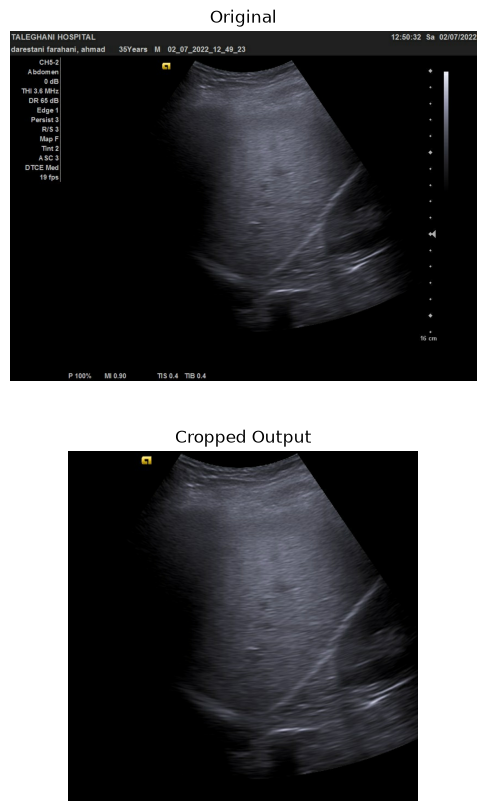

In [46]:
# Determine crop and resize

imgPath = imageMap.iloc[0]['Img Path']

img = tf.image.decode_image(
    tf.io.read_file(imgPath),
    channels = 3,
    expand_animations = False
    )

cropped = tf.image.crop_to_bounding_box(
    img,
    offset_height = 60,
    offset_width = 200,
    target_height = 640,
    target_width = 640,
)

# Plot Original
plt.figure(figsize = (8, 10))
plt.subplot(2, 1, 1)
plt.imshow(img.numpy().astype('uint8'))
plt.title("Original")
plt.axis('off')

# Plot Cropped
plt.subplot(2, 1, 2)
plt.imshow(cropped.numpy().astype('uint8'))
plt.title("Cropped Output")
plt.axis('off')

In [47]:
def loadAndPreprocess(filePath, label):
    img = tf.io.read_file(filePath)

    img = tf.image.decode_image(img, channels = 3)
    img.set_shape([None, None, 3])

    img = tf.image.crop_to_bounding_box(
        img,
        offset_height = 60,
        offset_width = 200,
        target_height = 640,
        target_width = 640,
    )

    img = tf.image.convert_image_dtype(img, tf.float32)

    return img, label

def trainAugment(img, label):
    img = tf.image.random_flip_left_right(img)
    img = tf.image.random_brightness(img, max_delta = 0.1)
    img = tf.image.random_contrast(img, lower = 0.9, upper = 1.1)

    return img, label

def createTensorflowDataset(df, imgCol, labelCol, isTrain = True):
    imgPaths = df[imgCol].values
    labels = df[labelCol].values

    imagePathsTensor = tf.constant(imgPaths)
    labelsTensor = tf.constant(labels, dtype = tf.int16)

    dataset = tf.data.Dataset.from_tensor_slices(
        (imagePathsTensor, labelsTensor)
    )

    dataset = dataset.map(loadAndPreprocess, num_parallel_calls = tf.data.AUTOTUNE)

    if isTrain:
        dataset = dataset.map(trainAugment, num_parallel_calls = tf.data.AUTOTUNE)
        dataset = dataset.shuffle(buffer_size = len(df))

    dataset = dataset.batch(batch_size = 32).prefetch(tf.data.AUTOTUNE)

    return dataset


In [48]:
x = createTensorflowDataset(imageMap, 'Img Path', 'Steatosis stage')